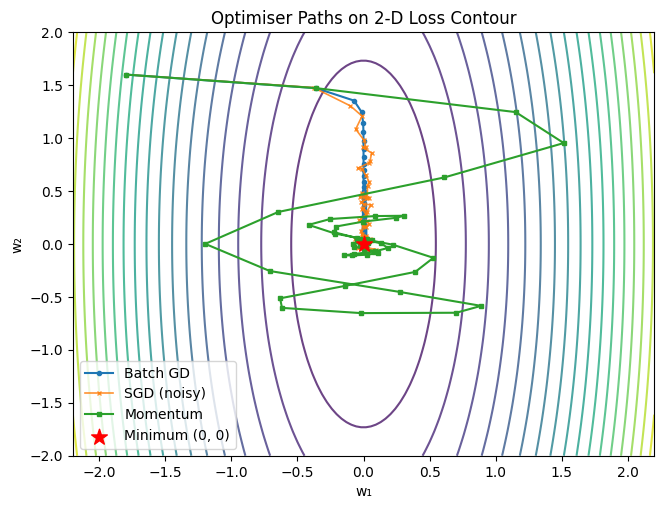

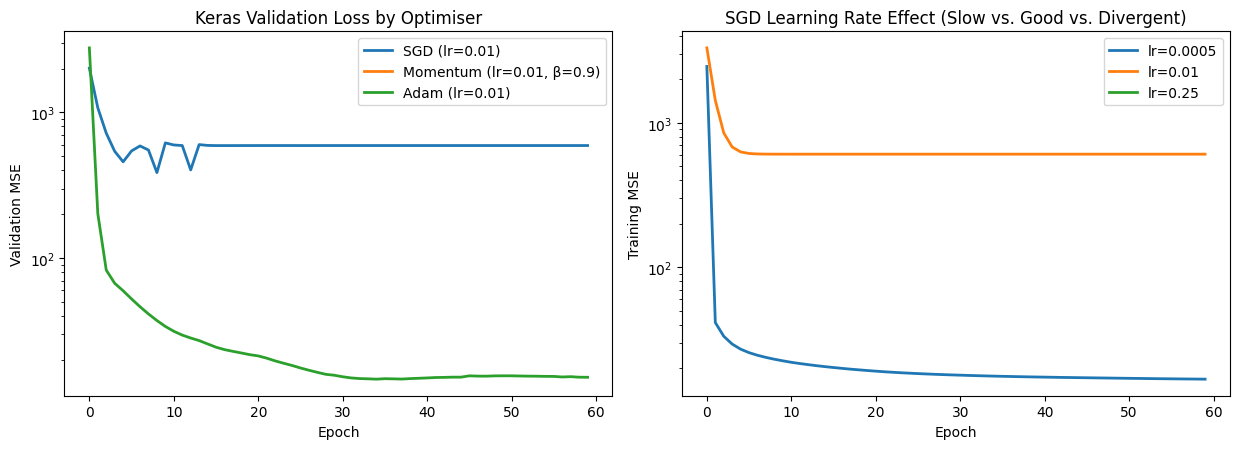

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# 1. Scratch implementations on an elongated 2-D quadratic loss surface
# L(w1, w2) = 0.5 * (10 * w1^2 + w2^2)
def loss_2d(w):
    return 0.5 * (10.0 * w[0] ** 2 + w[1] ** 2)

def grad_2d(w):
    return np.array([10.0 * w[0], w[1]])

w_init = np.array([-1.8, 1.6])
steps = 60
lr_scratch = 0.08

# Batch GD
w = w_init.copy()
path_bgd = [w.copy()]
for _ in range(steps):
    w = w - lr_scratch * grad_2d(w)
    path_bgd.append(w.copy())
path_bgd = np.array(path_bgd)

# SGD (with noisy gradient estimate)
w = w_init.copy()
path_sgd = [w.copy()]
for _ in range(steps):
    noisy_g = grad_2d(w) + np.random.normal(0, 0.45, size=2)
    w = w - lr_scratch * noisy_g
    path_sgd.append(w.copy())
path_sgd = np.array(path_sgd)

# Momentum
w = w_init.copy()
v = np.zeros(2)
beta = 0.85
path_mom = [w.copy()]
for _ in range(steps):
    v = beta * v + lr_scratch * grad_2d(w)
    w = w - v
    path_mom.append(w.copy())
path_mom = np.array(path_mom)

# Plot 2-D loss contour and optimiser trajectories
w1_grid, w2_grid = np.meshgrid(np.linspace(-2.2, 2.2, 120), np.linspace(-2.0, 2.0, 120))
Z_loss = 0.5 * (10.0 * w1_grid ** 2 + w2_grid ** 2)

plt.figure(figsize=(7.5, 5.5))
plt.contour(w1_grid, w2_grid, Z_loss, levels=25, cmap="viridis", alpha=0.8)
plt.plot(path_bgd[:, 0], path_bgd[:, 1], "o-", markersize=3, lw=1.5, label="Batch GD")
plt.plot(path_sgd[:, 0], path_sgd[:, 1], "x-", markersize=3, lw=1.2, alpha=0.85, label="SGD (noisy)")
plt.plot(path_mom[:, 0], path_mom[:, 1], "s-", markersize=3, lw=1.5, label="Momentum")
plt.scatter([0], [0], color="red", marker="*", s=140, zorder=6, label="Minimum (0, 0)")
plt.xlabel("w₁")
plt.ylabel("w₂")
plt.title("Optimiser Paths on 2-D Loss Contour")
plt.legend()
plt.savefig("exp06_2d_loss_contours.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Keras regression on synthetic delivery-time dataset
n_deliv = 1200
distance = np.random.uniform(1.0, 25.0, n_deliv)       # km
traffic = np.random.uniform(0.1, 1.0, n_deliv)         # traffic index
weight = np.random.uniform(0.5, 15.0, n_deliv)         # kg
time_of_day = np.random.uniform(6.0, 23.0, n_deliv)    # hour (0-24)

# Peak rush hours around 9am and 6pm
rush_boost = 8.0 * np.exp(-0.5 * ((time_of_day - 9) / 1.5) ** 2) + \
             10.0 * np.exp(-0.5 * ((time_of_day - 18.5) / 1.8) ** 2)
delivery_time = (
    8.0
    + 2.4 * distance
    + 16.0 * traffic * (distance / 10.0)
    + 0.7 * weight
    + rush_boost
    + np.random.normal(0, 3.0, n_deliv)
)

X_deliv = np.column_stack([distance, traffic, weight, time_of_day])
X_tr, X_te, y_tr, y_te = train_test_split(X_deliv, delivery_time, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

def build_reg_model():
    return keras.Sequential([
        layers.Input(shape=(4,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

opt_configs = {
    "SGD (lr=0.01)": keras.optimizers.SGD(learning_rate=0.01),
    "Momentum (lr=0.01, β=0.9)": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam (lr=0.01)": keras.optimizers.Adam(learning_rate=0.01),
}

histories = {}
for name, opt in opt_configs.items():
    tf.random.set_seed(42)
    m = build_reg_model()
    m.compile(optimizer=opt, loss="mse")
    h = m.fit(X_tr_s, y_tr, validation_data=(X_te_s, y_te), epochs=60, batch_size=32, verbose=0)
    histories[name] = h.history["val_loss"]

# 3. Learning rate variation test with SGD
lr_tests = {}
for lr_val in [0.0005, 0.01, 0.25]:
    tf.random.set_seed(42)
    m = build_reg_model()
    m.compile(optimizer=keras.optimizers.SGD(learning_rate=lr_val), loss="mse")
    h = m.fit(X_tr_s, y_tr, epochs=60, batch_size=32, verbose=0)
    lr_tests[f"lr={lr_val}"] = h.history["loss"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

for name, vloss in histories.items():
    axes[0].plot(vloss, lw=2, label=name)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation MSE")
axes[0].set_title("Keras Validation Loss by Optimiser")
axes[0].set_yscale("log")
axes[0].legend()

for label, tr_loss in lr_tests.items():
    clipped = np.clip(tr_loss, 0, 1e6)
    axes[1].plot(clipped, lw=2, label=label)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training MSE")
axes[1].set_title("SGD Learning Rate Effect (Slow vs. Good vs. Divergent)")
axes[1].set_yscale("log")
axes[1].legend()

plt.tight_layout()
plt.savefig("exp06_keras_optimisers_lr.png", dpi=150, bbox_inches="tight")
plt.show()